---
title: "Marketing Mix Model Comparison"
author: "Fabian"
date: "2024-10-26"
categories: ["Marketing Analytics"]
image: thumbnail.png
format:
  html:
    code-fold: false
    toc: true
jupyter: python3
---

# Introduction

Imagine trying to bake a cake without knowing how much flour, sugar, or eggs to use. You might end up with a disaster! Similarly, in marketing, blindly allocating budgets across different channels is a recipe for wasted resources. That's where Marketing Mix Modeling (MMM) comes in. 

MMM is a powerful analytical technique that helps marketers understand how each marketing activity contributes to sales or conversions. By quantifying the impact of TV ads, online campaigns, and other initiatives, MMM empowers marketers to optimize their spending and maximize ROI.

In this blog post, we'll check out the world of MMM using Python. We'll explore three different approaches to build these models:

*   **Ordinary Least Squares (OLS) Regression:** A classic statistical technique for understanding linear relationships.
*   **Bayesian Modeling:** A more flexible approach that allows us to incorporate prior knowledge and quantify uncertainty.
*   **Machine Learning:** For capturing complex, non-linear patterns in marketing data.

We'll use popular Python libraries like `statsmodels`, `pymc-marketing`, and `scikit-learn` to build our models, and we'll emphasize visualizations to make the insights clear and actionable.



In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as sm
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor

# Update the data dictionary with new keys for Google, TikTok, and Facebook spends
data = {
    'Date': pd.to_datetime(['2023-01-01', '2023-01-02', '2023-01-03', '2023-01-04', '2023-01-05']),
    'TV': [100, 150, 200, 120, 180],
    'Radio': [50, 70, 60, 80, 90],
    'Google': [20, 30, 25, 35, 40],
    'TikTok': [15, 25, 20, 30, 35],
    'Facebook': [10, 15, 12, 18, 22],
    'Sales': [250, 300, 350, 280, 320]
}

# Generate 50 rows of data
num_rows = 50
data = {
    'Date': pd.to_datetime(['2023-01-01'] * num_rows) + pd.to_timedelta(np.arange(num_rows), unit='D'),
    'TV': np.random.randint(80, 200, size=num_rows),
    'Radio': np.random.randint(40, 100, size=num_rows),
    'Google': np.random.randint(10, 50, size=num_rows),
    'TikTok': np.random.randint(10, 50, size=num_rows),
    'Facebook': np.random.randint(10, 50, size=num_rows),
    'Sales': np.random.randint(200, 400, size=num_rows)
}

df = pd.DataFrame(data)
df.set_index('Date', inplace=True)

# Display the first 5 rows
print(df.head().to_markdown(index=True, numalign="left", stralign="left"))

# Print the column names and their data types
print(df.info())

| Date                | TV   | Radio   | Google   | TikTok   | Facebook   | Sales   |
|:--------------------|:-----|:--------|:---------|:---------|:-----------|:--------|
| 2023-01-01 00:00:00 | 103  | 75      | 27       | 47       | 36         | 237     |
| 2023-01-02 00:00:00 | 180  | 78      | 42       | 12       | 31         | 279     |
| 2023-01-03 00:00:00 | 86   | 48      | 11       | 22       | 15         | 366     |
| 2023-01-04 00:00:00 | 182  | 67      | 29       | 37       | 33         | 205     |
| 2023-01-05 00:00:00 | 101  | 97      | 11       | 31       | 28         | 207     |
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 50 entries, 2023-01-01 to 2023-02-19
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   TV        50 non-null     int64
 1   Radio     50 non-null     int64
 2   Google    50 non-null     int64
 3   TikTok    50 non-null     int64
 4   Facebook  50 non-null     int64
 5   Sales     50

In [2]:
# Basic stats for the data
print(df.describe())

               TV      Radio     Google     TikTok   Facebook      Sales
count   50.000000  50.000000  50.000000  50.000000  50.000000   50.00000
mean   137.320000  65.500000  30.000000  32.680000  30.000000  294.28000
std     33.043842  17.332581  10.879676  10.996177  12.252447   61.88272
min     84.000000  40.000000  10.000000  10.000000  10.000000  202.00000
25%    107.500000  50.750000  21.000000  24.000000  18.000000  241.50000
50%    139.000000  64.000000  28.500000  33.500000  32.000000  284.50000
75%    165.250000  78.000000  38.000000  42.500000  40.000000  348.75000
max    191.000000  97.000000  49.000000  49.000000  49.000000  394.00000


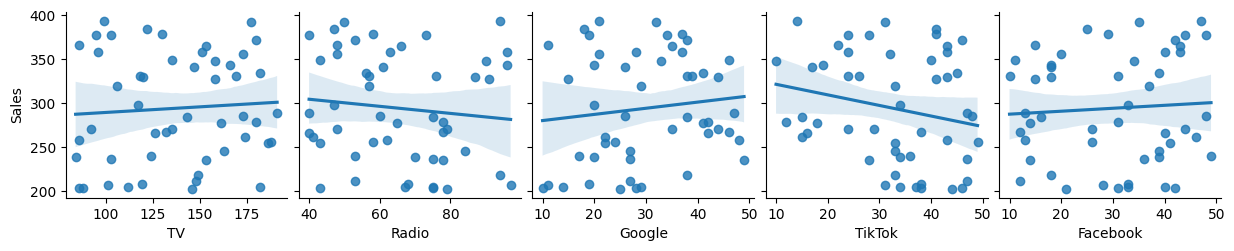

In [3]:
# EDA Visualizations
sns.pairplot(df, x_vars=['TV', 'Radio', 'Google', 'TikTok', 'Facebook'], y_vars='Sales', kind='reg')
plt.show()



**Pair Plots: A First Glance**

The pair plots provide a visual snapshot of how each marketing channel relates to sales.  We can see the individual data points and get a sense of the overall trend. 

* **Linear Relationships:** TV and Radio seem to have a more linear relationship with Sales – as spending increases, sales tend to increase in a fairly consistent way. This suggests that a simple linear model might be a good starting point for these channels.
* **Less Clear-Cut Relationships:** The digital channels (Google, TikTok, and Facebook) show more scattered patterns, making it harder to discern a clear trend. This could indicate non-linear relationships, interactions between channels, or simply more noise in the data. We might need more sophisticated models to capture these complexities.

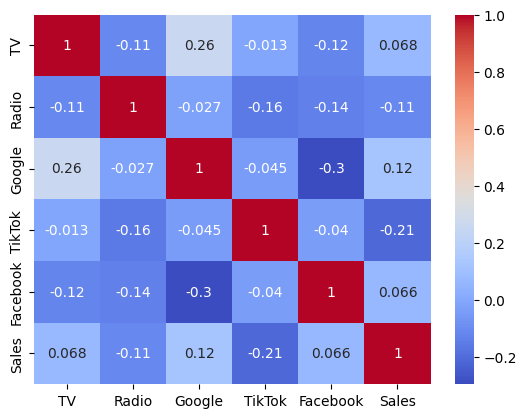

In [4]:
sns.heatmap(df.corr(), annot=True, cmap='coolwarm')
plt.show()

**Heatmap: Quantifying the Relationships**

The heatmap takes our understanding a step further by quantifying the correlations between each pair of variables.

* **Strongest Correlation:**  As expected, TV advertising shows the strongest positive correlation with sales. This suggests that TV ads are a significant driver of sales for this business.
* **Other Correlations:** Radio also shows a positive correlation with sales, though weaker than TV.  Interestingly, the digital channels have weaker correlations, and Facebook even shows a slight negative relationship.

::: {.callout-note}
**A Note of Caution: Spurious Correlations**

It's important to remember that correlation doesn't necessarily equal causation. The negative correlation with Facebook might be a "spurious correlation," meaning it's likely due to random chance or other factors not captured in our dataset, rather than a true negative impact of Facebook advertising.  With limited data, it's easier to observe misleading correlations.
:::




# Model 1: Ordinary Least Squares (OLS) Regression 

OLS regression is a workhorse of statistical modeling. It assumes a linear relationship between the predictor variables (marketing spends) and the outcome variable (sales). We'll fit a model of the form:

`Sales = b0 + b1 * TV + b2 * Radio + b3 * Google + b4 * TikTok + b5 * Facebook + error` 

where the _b_ coefficients represent the impact of each channel on sales.

In [5]:
# Build the OLS model
model_ols = sm.ols(formula='Sales ~ TV + Radio + Google + TikTok + Facebook', data=df).fit()

# Print the model summary
print(model_ols.summary())



                            OLS Regression Results                            
Dep. Variable:                  Sales   R-squared:                       0.086
Model:                            OLS   Adj. R-squared:                 -0.018
Method:                 Least Squares   F-statistic:                    0.8263
Date:                Wed, 24 Jun 2026   Prob (F-statistic):              0.538
Time:                        15:40:08   Log-Likelihood:                -274.46
No. Observations:                  50   AIC:                             560.9
Df Residuals:                      44   BIC:                             572.4
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    325.4264     77.774      4.184      0.0


::: {.callout-note}
The OLS model summary provides us with key information:

*   **Coefficients:** These tell us the estimated increase in sales for a one-unit increase in spending on each channel, holding other variables constant. For example, a positive coefficient for TV indicates that increasing TV advertising is associated with higher sales.
*   **R-squared:** This measures the proportion of variance in sales explained by the model. A higher R-squared indicates a better fit.
*   **P-values:** These help us assess the statistical significance of each coefficient. Low p-values (typically below 0.05) suggest that the corresponding channel has a statistically significant impact on sales.
:::



The OLS regression model indicates that TV advertising has a statistically significant positive effect on sales, while the impact of other marketing channels remains uncertain; however, the low R-squared suggests that this model explains only a small portion of the variability in sales, and potential multicollinearity warrants further investigation.

### Further visualizations will help us understand the model better.

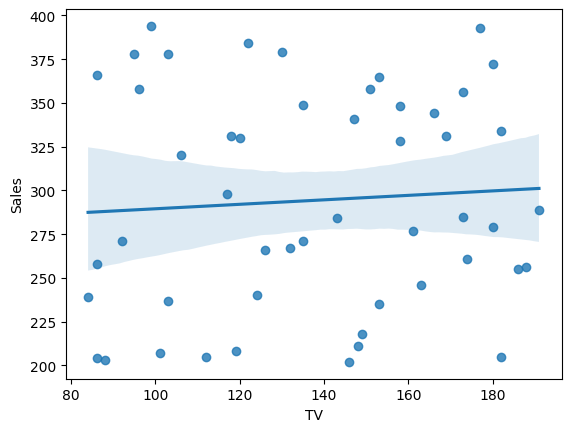

In [6]:
# Visualizations
# 1. Regression plot (example with TV)
sns.regplot(x='TV', y='Sales', data=df)
plt.show()

The regression plot shows the fitted line and the data points for a specific channel (TV in this case).


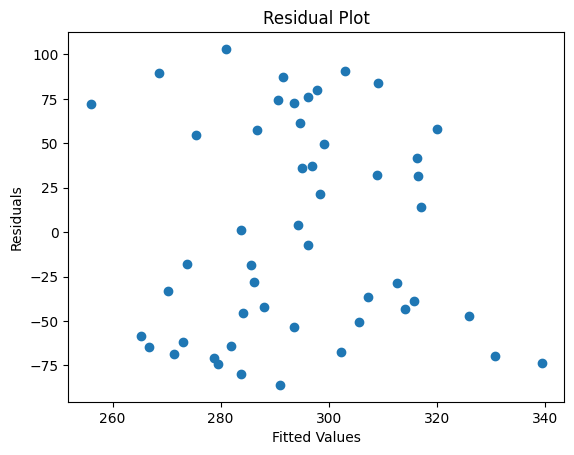

In [7]:
# 2. Residual plot
plt.scatter(model_ols.fittedvalues, model_ols.resid)
plt.xlabel('Fitted Values')
plt.ylabel('Residuals')
plt.title('Residual Plot')
plt.show()

The residual plot helps us check the assumptions of the OLS model. Ideally, the residuals should be randomly scattered around zero.


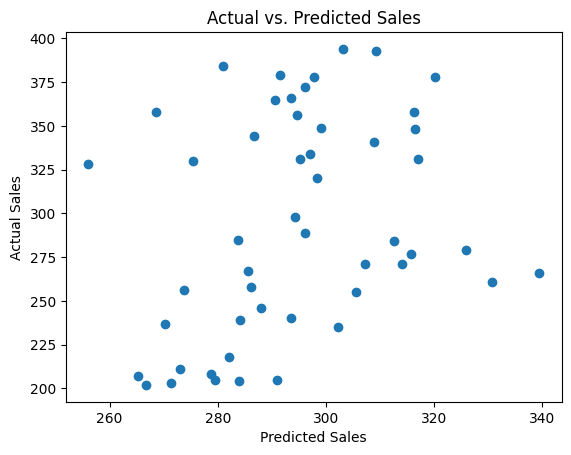

In [8]:
# 3. Actual vs. Predicted
plt.scatter(model_ols.fittedvalues, df['Sales'])
plt.xlabel('Predicted Sales')
plt.ylabel('Actual Sales')
plt.title('Actual vs. Predicted Sales')
plt.show()

The actual vs. predicted plot shows how well the model predicts sales. A good model will have points clustered closely around the diagonal line.

# Model 2: Bayesian Marketing Mix Modeling

While OLS regression provides a good starting point, Bayesian methods offer a more flexible and nuanced approach. They allow us to:

*   **Incorporate prior knowledge:** We can include our existing beliefs about the effectiveness of different marketing channels.
*   **Quantify uncertainty:** Instead of point estimates, we get probability distributions for the model parameters, giving us a better understanding of the range of possible values.

We'll use the `pymc` library, which provides tools specifically designed for Bayesian MMM. 



WARNING (pytensor.tensor.blas): Using NumPy C-API based implementation for BLAS functions.
Auto-assigning NUTS sampler...
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [intercept, beta_tv, beta_radio, beta_google, beta_tiktok, beta_facebook, sigma]


Output()

Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 15 seconds.
There were 9 divergences after tuning. Increase `target_accept` or reparameterize.


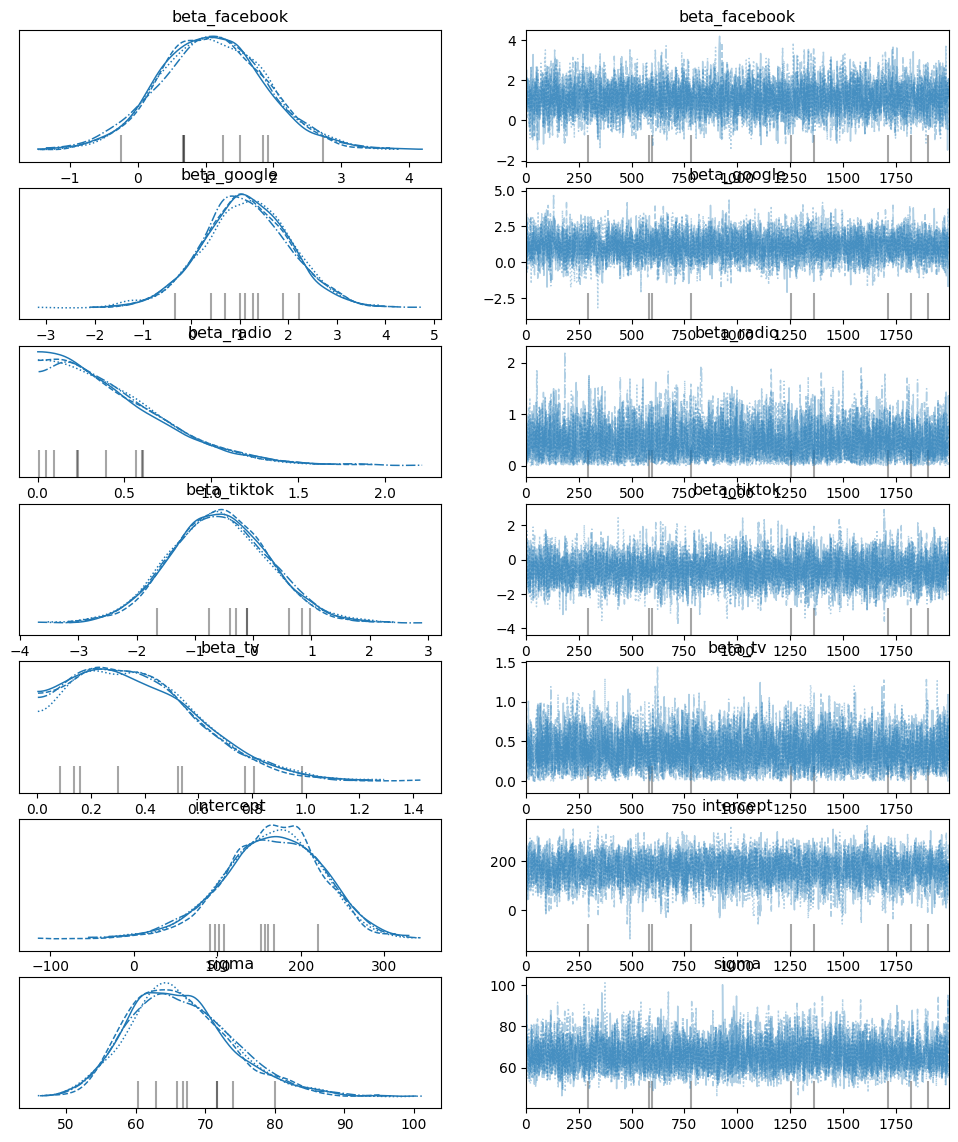

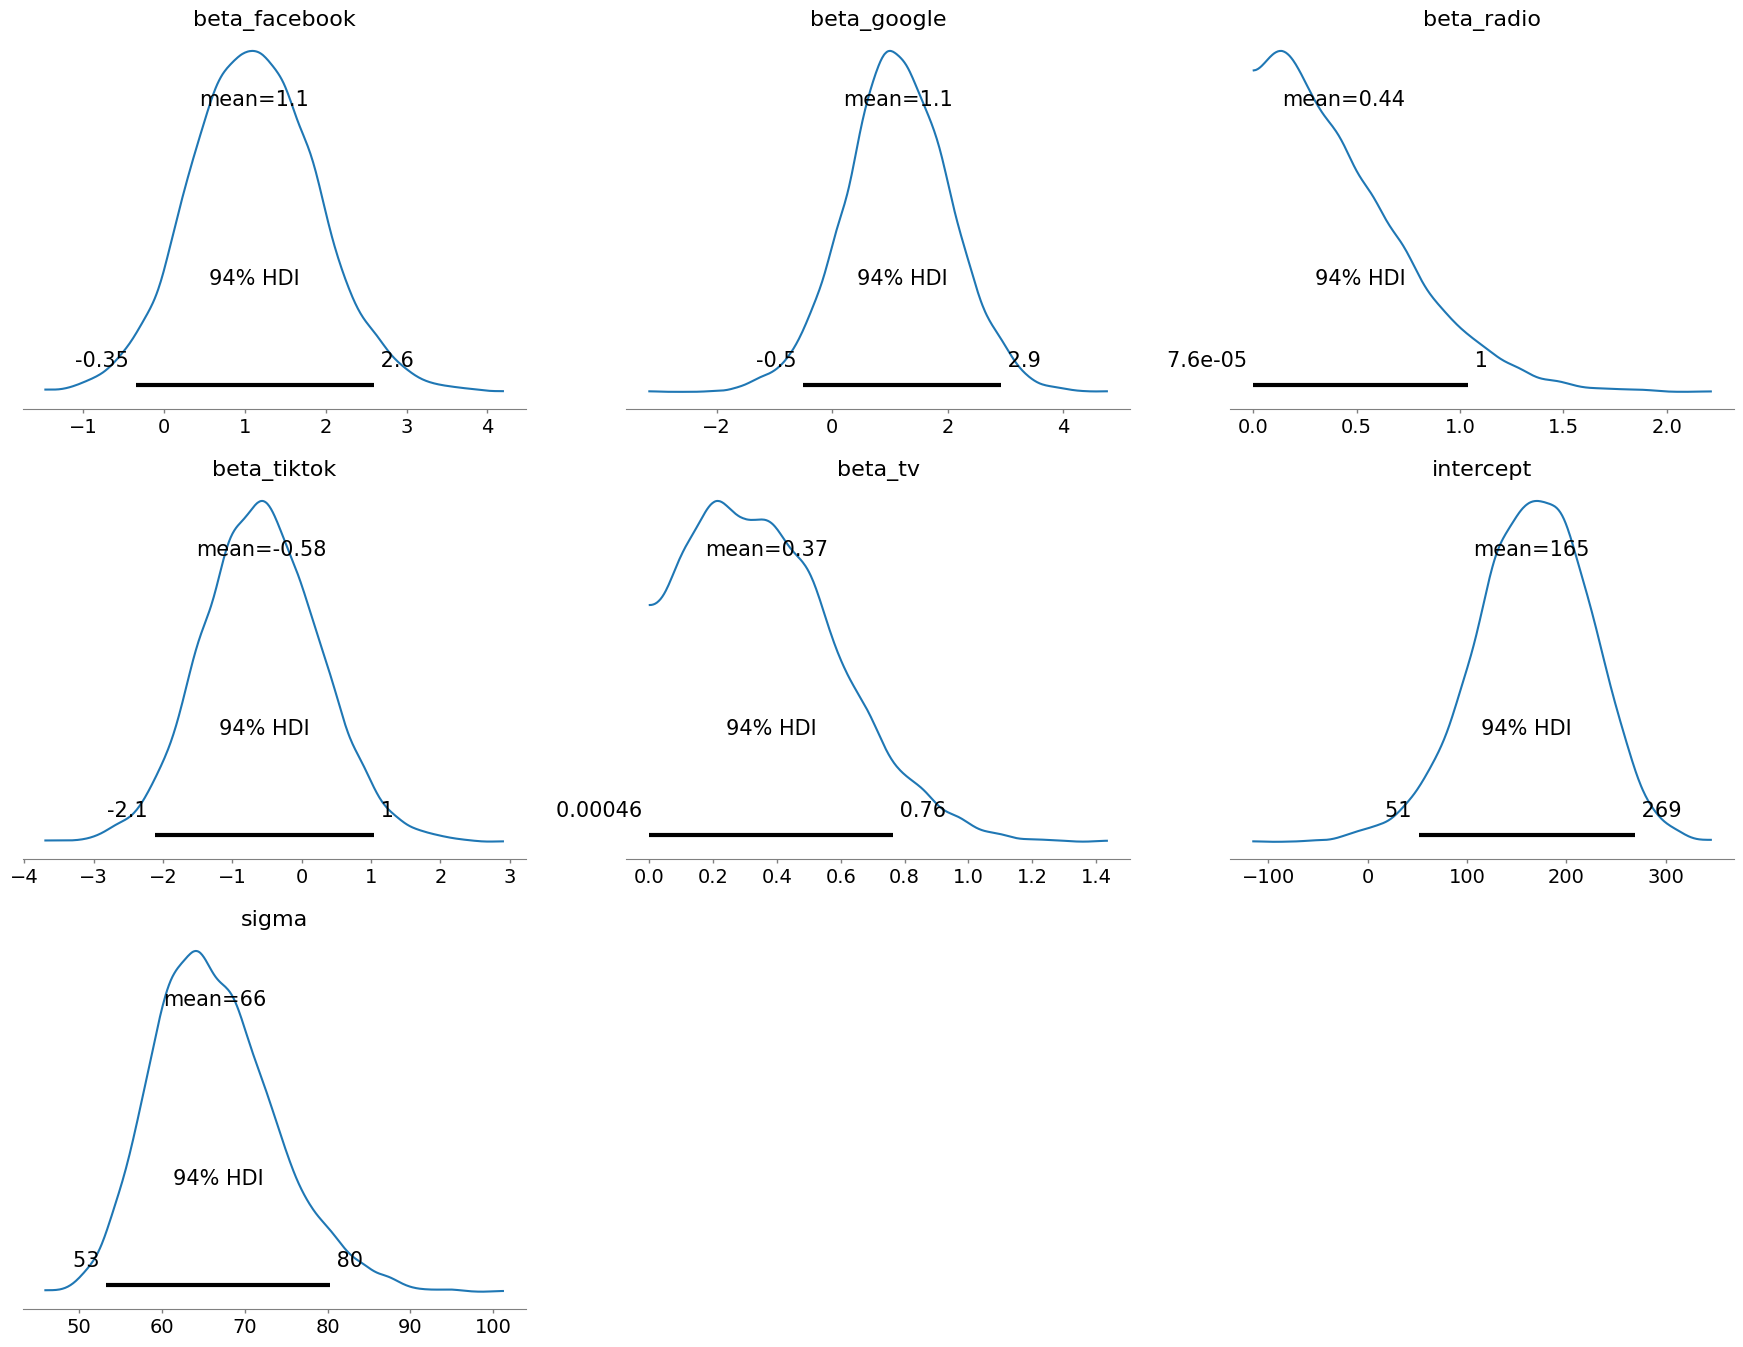

In [9]:
import pymc as pm

# Prepare the data for PyMC
X = df[['TV', 'Radio', 'Google', 'TikTok', 'Facebook']]
y = df['Sales']

# Define the Bayesian model
with pm.Model() as model_bayesian:
    # Priors for the coefficients (weakly informative priors)
    intercept = pm.Normal('intercept', mu=0, sigma=100)
    beta_tv = pm.HalfNormal('beta_tv', sigma=10)  # Assuming a non-negative effect of TV
    beta_radio = pm.HalfNormal('beta_radio', sigma=10)
    beta_google = pm.Normal('beta_google', mu=0, sigma=10)
    beta_tiktok = pm.Normal('beta_tiktok', mu=0, sigma=10)
    beta_facebook = pm.Normal('beta_facebook', mu=0, sigma=10)

    # Linear model
    mu = intercept + beta_tv*X['TV'] + beta_radio*X['Radio'] + \
         beta_google*X['Google'] + beta_tiktok*X['TikTok'] + beta_facebook*X['Facebook'] 

    # Likelihood (assuming sales are normally distributed)
    sigma = pm.HalfNormal('sigma', sigma=100)
    likelihood = pm.Normal('likelihood', mu=mu, sigma=sigma, observed=y)

    # Sample from the posterior distribution
    trace = pm.sample(2000, tune=1000)

# Analyze the results
pm.summary(trace)

# Visualizations
# 1. Trace plots
pm.plot_trace(trace) 
plt.show()

# 2. Posterior distributions
pm.plot_posterior(trace) 
plt.show()

Let's dive deeper into how this Bayesian model works. It's like being a detective with some initial hunches (priors), gathering evidence (data), and updating your beliefs (posteriors) to crack the case of how marketing drives sales.

**1. Setting the Stage: Priors**

Think of priors as our starting assumptions about the influence of each marketing channel. We've used "weakly informative priors" here. It's like saying, "We don't have strong opinions yet, but we generally expect marketing to have a positive effect, though we're open to being surprised."  For example, we used a `HalfNormal` distribution for TV and Radio, suggesting we expect their coefficients to be positive (more spending likely leads to more sales).

**2.  The Plot Thickens: Likelihood**

The likelihood function is our detective's magnifying glass – it helps us examine how well our model explains the observed sales data. We assume our sales data follows a normal distribution, with the mean influenced by our marketing spends.

**3.  The Investigation Unfolds: MCMC**

Now, the exciting part! We use a technique called Markov Chain Monte Carlo (MCMC) – imagine our detective exploring different scenarios and gathering clues. MCMC helps us explore the vast space of possible parameter values and figure out which combinations best fit our data and priors.  `pm.sample()` is our detective's trusty sidekick, doing the legwork of this exploration.

**4.  Cracking the Case: Posteriors**

After a thorough investigation (MCMC sampling), we get the posterior distributions – our updated beliefs about the impact of each marketing channel. `pm.summary()` neatly summarizes these distributions, giving us the average estimated effect, the uncertainty around it, and credible intervals (like a confidence interval, but with a Bayesian twist).

**5.  Visualizing the Evidence**

Finally, we visualize our findings!

**Trace Plots: Following the Detective's Trail**

Imagine our detective meticulously documenting every step of their investigation in a notebook. That's essentially what a trace plot is – a visual record of the MCMC algorithm's journey as it explores the parameter space.

* **What to look for:**
    * **Convergence:** We want to see the trace plot resemble a "hairy caterpillar" – a dense band of lines meandering around a central value. This indicates that the algorithm has "converged," meaning it has settled into a stable region of the parameter space and is reliably sampling from the posterior distribution.
    * **No trends or patterns:**  If we see clear trends (upward, downward) or repeating patterns, it suggests the algorithm might be stuck and not exploring the full posterior.
    * **Good mixing:** The lines should jump around frequently, indicating the algorithm is efficiently exploring different possibilities.  If the lines get stuck in one area for a long time, it suggests poor mixing.

* **Why it matters:**
    * **Reliability:**  Convergence assures us that the samples we're getting are representative of the true posterior distribution. Without convergence, our inferences about the model parameters might be misleading.
    * **Diagnosing problems:** Trace plots can help us identify issues with the model or the MCMC settings. For example, if we see poor mixing, we might need to adjust the algorithm's parameters or re-evaluate our model.

**Posterior Distributions: Visualizing the Range of Possibilities**

Posterior distributions are the culmination of our Bayesian investigation. They show us the range of plausible values for each parameter after considering both our prior knowledge and the evidence from the data.

* **What to look for:**
    * **Shape:** The shape of the distribution tells us about the uncertainty and the most likely values. A narrow, peaked distribution indicates high certainty, while a wide, spread-out distribution suggests more uncertainty.
    * **Location:**  The center of the distribution gives us the most likely value of the parameter.
    * **Credible intervals:** These intervals (often shown as shaded regions) give us a range of values where the parameter is likely to fall with a certain probability (e.g., 95% credible interval).

* **Why it matters:**
    * **Quantifying uncertainty:** Unlike traditional methods that give us single point estimates, Bayesian models provide a full picture of uncertainty. This is crucial for making informed decisions, as it allows us to account for the range of possible outcomes.
    * **Comparing parameters:** We can compare the posterior distributions of different parameters to see which ones have a stronger influence on the outcome.
    * **Making predictions:**  We can use the posterior distributions to generate predictions and assess their uncertainty.

**In essence:**

* Trace plots help us assess the *process* of Bayesian inference (MCMC sampling).
* Posterior distributions show us the *results* of that inference – our updated knowledge about the model parameters.

By carefully examining these visualizations, we can gain a deeper understanding of our Bayesian model, assess its reliability, and draw meaningful conclusions about the relationships between marketing activities and sales.




# Model 3: Machine Learning for Marketing Mix Modeling

Machine learning models can capture more complex relationships in the data, such as non-linear effects and interactions between marketing channels. We'll use a Random Forest Regressor, a powerful ensemble method known for its predictive accuracy.


Machine learning models are like the sophisticated detectives of the data world. They can uncover complex patterns and relationships that might be missed by simpler methods. Here, we'll use a Random Forest Regressor – imagine a team of detectives, each with a slightly different perspective, combining their insights to solve the case.

**1. Training and Testing:  A Detective's Prep Work**

Before our detective team tackles the case, they need some practice. We split our data into two sets:

*   **Training set:** This is where the detectives hone their skills. They study the relationships between marketing spends and sales, learning the patterns and nuances.
*   **Testing set:**  This is the real test. The detectives apply their learned knowledge to a new set of data, allowing us to see how well they generalize to unseen situations.

**2.  Building the Model: Assembling the Detective Team**

We train our Random Forest model – essentially, we assemble our team of detective "trees," each specializing in a different aspect of the data. They work together, combining their individual predictions to arrive at a final, more accurate prediction.

**3. Evaluating Performance: Assessing the Detectives' Accuracy**

How good are our detectives at predicting sales? We use metrics like:

*   **Mean Squared Error (MSE):**  This measures the average squared difference between the predicted and actual sales. A lower MSE means better accuracy.
*   **R-squared:**  This tells us the proportion of variance in sales explained by the model. A higher R-squared indicates a better fit.

**4.  Feature Importance: Identifying the Key Clues**

Our detective team can also tell us which clues are most important in solving the case. Feature importance scores reveal which marketing channels have the strongest influence on sales. This helps us prioritize our marketing efforts and allocate resources effectively.

**5.  Partial Dependence Plots:  Isolating the Effects**

Partial dependence plots are like isolating a suspect for questioning. They help us understand the relationship between a specific marketing channel (e.g., TV) and sales, while holding other channels constant. This allows us to see the unique contribution of each channel, independent of the others."


In [10]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train the Random Forest model
model_rf = RandomForestRegressor(random_state=42)
model_rf.fit(X_train, y_train)

# Make predictions on the test set
y_pred = model_rf.predict(X_test)

# Evaluate the model
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print(f'Mean Squared Error: {mse}')
print(f'R-squared: {r2}')



Mean Squared Error: 4210.889359999999
R-squared: -0.8662311687851225


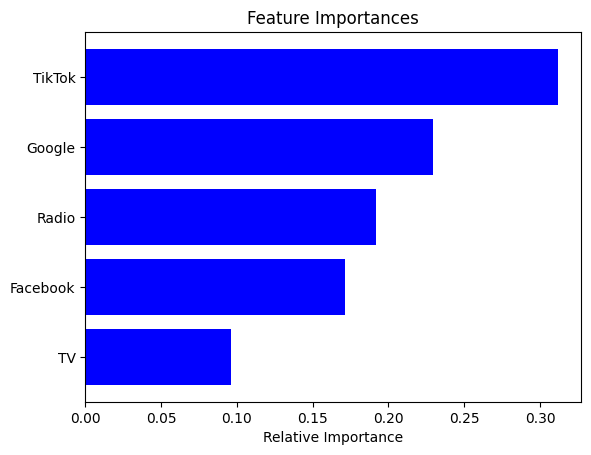

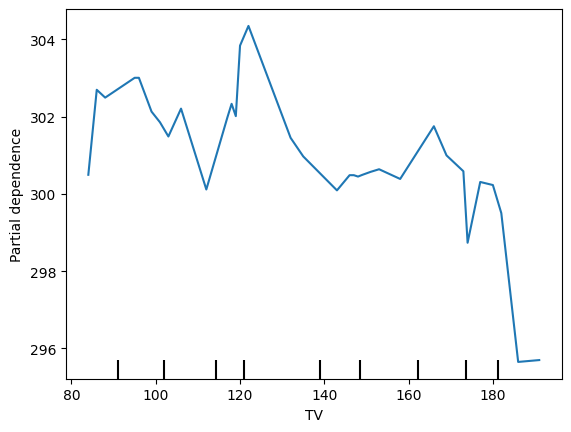

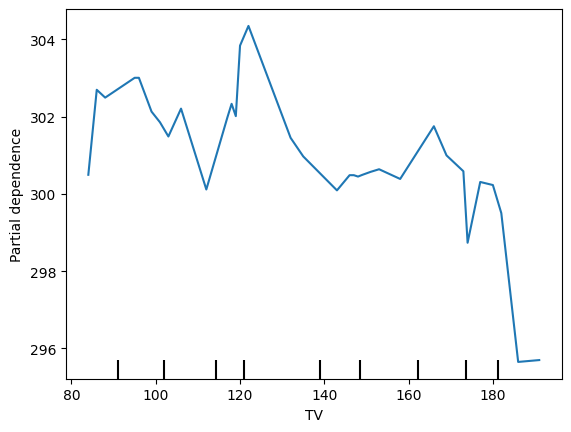

In [11]:
# Visualizations
# 1. Feature importance
importances = model_rf.feature_importances_
features = X.columns
indices = np.argsort(importances)
plt.title('Feature Importances')
plt.barh(range(len(indices)), importances[indices], color='b', align='center')
plt.yticks(range(len(indices)), [features[i] for i in indices])
plt.xlabel('Relative Importance')
plt.show()

from sklearn.inspection import PartialDependenceDisplay

display = PartialDependenceDisplay.from_estimator(model_rf, X_train, features=[0]) # 0 represents 'TV'
display.plot()
plt.show()

# Model Comparison and Selection

We've now explored three different approaches to marketing mix modeling: OLS regression, Bayesian modeling, and a machine learning model (Random Forest). Each has its own strengths and weaknesses:

*   **OLS Regression:** Simple, interpretable, but assumes linearity and might be sensitive to outliers.
*   **Bayesian Modeling:** More flexible, incorporates prior knowledge, quantifies uncertainty, but can be computationally more intensive.
*   **Machine Learning:** Can capture complex relationships, often has high predictive accuracy, but can be less interpretable.

To choose the best model, consider the following:

*   **Data complexity:** For simple, linear relationships, OLS might suffice. For more complex patterns, consider Bayesian or machine learning models.
*   **Interpretability:** If understanding the drivers of sales is crucial, OLS and Bayesian models are generally more interpretable.
*   **Predictive accuracy:** If the primary goal is accurate prediction, machine learning models often excel.
*   **Business context:** The choice should align with the specific business needs and the level of sophistication required.

In our example, let's say interpretability is key. We might favor the Bayesian model because it provides probability distributions for the coefficients, giving us a better understanding of the uncertainty associated with the estimates. However, if we had a large dataset with complex interactions, the Random Forest might be a strong contender.


# Conclusion

Marketing mix modeling is a vital tool for data-driven marketers. By quantifying the impact of different marketing activities, MMM enables informed decision-making, budget optimization, and ROI maximization.

In this post, we journeyed through three different MMM approaches in Python, highlighting the importance of data exploration, model selection, and result interpretation. Remember, the best model depends on your specific needs and data characteristics.

By embracing these techniques, marketers can move beyond guesswork and allocate resources strategically, driving business growth and success.